# Actividad: Partición de grafos (bisección)

**Curso:** Diseño de algoritmos matemáticos bioinspirados — **Profesor:** Fernando Elizalde Ramírez

Dado el grafo $G=(V,E)$ de la presentación `biseccion_grafos.pptx` ($|V|=16$, $|E|=28$), se busca partir los nodos en dos
conjuntos de 8 nodos minimizando el número de aristas que cruzan entre ambos conjuntos (el *corte*).

Contenido:
1. Datos del problema y representación del grafo.
2. Óptimo exacto por enumeración (para validar al AG).
3. Algoritmo genético: operadores.
4. Ejemplo de una iteración con 4 padres (el mismo que se desarrolla a mano en el reporte).
5. AG con población de 20 individuos: 30 corridas independientes.
6. Mejor solución representada en el grafo.

In [1]:
import time, itertools
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

IMG = Path('Images'); IMG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8a8a'

## 1. Datos del problema y operadores del AG

**Cromosoma:** vector binario $x\in\{0,1\}^{16}$; $x_i=1$ si el nodo $i$ va a la partición $A$ y $x_i=0$ si va a $B$.
**Factible** si tiene exactamente 8 unos. **Fitness** (a minimizar): número de aristas cortadas
$f(x)=\sum_{(i,j)\in E}|x_i-x_j|$.

Operadores: torneo binario, cruza de un punto ($p_c=0.9$), reparación aleatoria, mutación por intercambio ($p_m=0.2$ por hijo)
y reemplazo $(\mu+\lambda)$ sin duplicados.

In [2]:
import numpy as np
N = 16
E = [(1,2),(1,9),(1,14),(2,3),(2,5),(3,4),(3,5),(3,6),(3,7),(4,6),(5,7),(5,9),(5,10),(6,7),
     (6,8),(7,8),(7,11),(8,11),(9,10),(9,13),(9,14),(10,11),(10,12),(12,16),(13,15),(13,16),
     (14,15),(15,16)]
EU = np.array([u - 1 for u, v in E]); EV = np.array([v - 1 for u, v in E])

def corte(x):
    """Número de aristas cuyos extremos quedan en particiones distintas."""
    return int(np.sum(x[EU] != x[EV]))

def es_factible(x):
    return int(x.sum()) == N // 2

def inicializar(rng):
    x = np.zeros(N, dtype=int)
    x[rng.choice(N, N // 2, replace=False)] = 1
    return x

def torneo(pob, fit, rng, log=None):
    i, j = rng.choice(len(pob), 2, replace=False)
    g = i if fit[i] <= fit[j] else j
    if log is not None: log.append(('torneo', int(i), int(j), int(g)))
    return pob[g].copy()

def cruza_un_punto(p1, p2, pc, rng, log=None):
    r = rng.random()
    if r >= pc:
        if log is not None: log.append(('cruza', float(r), None))
        return p1.copy(), p2.copy()
    k = int(rng.integers(1, N))       # lugar de cruce: entre el gen k y el k+1
    if log is not None: log.append(('cruza', float(r), k))
    return np.concatenate([p1[:k], p2[k:]]), np.concatenate([p2[:k], p1[k:]])

def reparar(x, rng, log=None):
    d = int(x.sum()) - N // 2
    pos = []
    if d > 0:
        pos = rng.choice(np.flatnonzero(x == 1), d, replace=False); x[pos] = 0
    elif d < 0:
        pos = rng.choice(np.flatnonzero(x == 0), -d, replace=False); x[pos] = 1
    if log is not None: log.append(('reparar', d, [int(p) + 1 for p in pos]))
    return x

def mutar(x, pm, rng, log=None):
    r = rng.random()
    if r < pm:
        i = int(rng.choice(np.flatnonzero(x == 1))); j = int(rng.choice(np.flatnonzero(x == 0)))
        x[i], x[j] = 0, 1
        if log is not None: log.append(('mutar', float(r), (i + 1, j + 1)))
    elif log is not None: log.append(('mutar', float(r), None))
    return x

def reemplazo(pob, hijos, mu):
    """(mu + lambda): se unen padres e hijos, se quitan duplicados y se quedan los mu mejores."""
    todos = list(pob) + list(hijos)
    unicos, vistos = [], set()
    for x in todos:
        if tuple(x) not in vistos: vistos.add(tuple(x)); unicos.append(x)
    unicos.sort(key=corte)
    if len(unicos) < mu:
        resto = sorted(todos, key=corte); unicos += resto[:mu - len(unicos)]
    return [x.copy() for x in unicos[:mu]]

def generacion(pob, rng, pc, pm, log=None):
    fit = [corte(x) for x in pob]
    hijos = []
    while len(hijos) < len(pob):
        p1 = torneo(pob, fit, rng, log); p2 = torneo(pob, fit, rng, log)
        for h in cruza_un_punto(p1, p2, pc, rng, log):
            h = reparar(h, rng, log)
            h = mutar(h, pm, rng, log)
            hijos.append(h)
    return reemplazo(pob, hijos[:len(pob)], len(pob)), hijos[:len(pob)]

def ag(tam_pob=20, pc=0.9, pm=0.2, max_gen=100, sin_mejora=30, semilla=None):
    rng = np.random.default_rng(semilla)
    pob = [inicializar(rng) for _ in range(tam_pob)]
    hist_mejor, hist_prom = [], []
    mejor, estancado = None, 0
    for g in range(max_gen):
        pob, _ = generacion(pob, rng, pc, pm)
        f = [corte(x) for x in pob]
        hist_mejor.append(min(f)); hist_prom.append(float(np.mean(f)))
        if mejor is None or min(f) < corte(mejor):
            mejor, estancado = pob[int(np.argmin(f))].copy(), 0
        else:
            estancado += 1
        if estancado >= sin_mejora: break
    return mejor, hist_mejor, hist_prom


## 2. Representación del grafo

|V| = 16, |E| = 28
Grados: {1: 3, 2: 3, 3: 5, 4: 2, 5: 5, 6: 4, 7: 5, 8: 3, 9: 5, 10: 4, 11: 3, 12: 2, 13: 3, 14: 3, 15: 3, 16: 3}


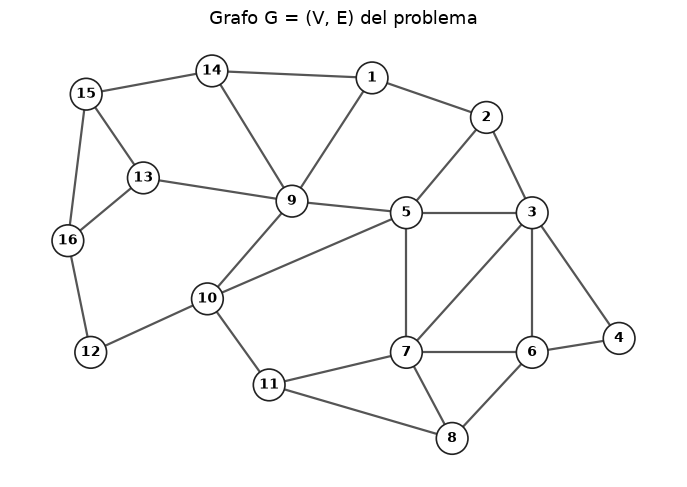

In [3]:
# Coordenadas aproximadas a las del dibujo de la presentación
POS = {1:(890,240), 2:(940,257), 3:(960,298), 4:(998,352), 5:(905,298), 6:(960,358), 7:(905,358),
       8:(925,395), 9:(855,293), 10:(818,335), 11:(845,372), 12:(767,358), 13:(790,283), 14:(820,237),
       15:(765,247), 16:(757,310)}
POS = {k: (x, -y) for k, (x, y) in POS.items()}
G = nx.Graph(); G.add_nodes_from(range(1, N + 1)); G.add_edges_from(E)
print(f'|V| = {G.number_of_nodes()}, |E| = {G.number_of_edges()}')
print('Grados:', dict(G.degree()))

def dibujar(x=None, titulo='', archivo=None):
    fig, ax = plt.subplots(figsize=(7, 5))
    if x is None:
        colores, cortadas, normales = ['white'] * N, [], E
    else:
        colores = [AZUL if x[i - 1] == 1 else NARANJA for i in G.nodes]
        cortadas = [(u, v) for u, v in E if x[u - 1] != x[v - 1]]
        normales = [(u, v) for u, v in E if x[u - 1] == x[v - 1]]
    nx.draw_networkx_edges(G, POS, edgelist=normales, width=1.6, edge_color='#555555', ax=ax)
    nx.draw_networkx_edges(G, POS, edgelist=cortadas, width=2.4, style='--', edge_color='#c0392b', ax=ax)
    nx.draw_networkx_nodes(G, POS, node_color=colores, edgecolors='#222222', linewidths=1.2, node_size=520, ax=ax)
    lab_col = {i: ('white' if x is not None else 'black') for i in G.nodes}
    for i, (px, py) in POS.items():
        ax.text(px, py, str(i), ha='center', va='center', fontsize=10, color=lab_col[i], fontweight='bold')
    if x is not None:
        from matplotlib.lines import Line2D
        h = [Line2D([], [], marker='o', ls='', mfc=AZUL, mec='#222', ms=11, label='Partición A'),
             Line2D([], [], marker='o', ls='', mfc=NARANJA, mec='#222', ms=11, label='Partición B'),
             Line2D([], [], color='#c0392b', ls='--', lw=2.4, label=f'Arista cortada ({len(cortadas)})')]
        ax.legend(handles=h, loc='lower left', frameon=False, fontsize=10)
    ax.set_title(titulo); ax.axis('off'); fig.tight_layout()
    if archivo: fig.savefig(IMG / archivo, dpi=200, bbox_inches='tight')
    plt.show()

dibujar(titulo='Grafo G = (V, E) del problema', archivo='grafo_original.png')

## 3. Óptimo exacto por enumeración

Hay $\binom{16}{8}=12\,870$ bisecciones; por simetría ($x$ y $1-x$ dan el mismo corte) basta fijar el nodo 1 en $A$ y
enumerar $\binom{15}{7}=6\,435$. El tamaño es pequeño, así que se puede obtener el óptimo y usarlo para evaluar al AG.

In [4]:
t0 = time.perf_counter()
cortes, optimos = [], []
for comb in itertools.combinations(range(1, N), N // 2 - 1):
    x = np.zeros(N, dtype=int); x[0] = 1; x[list(comb)] = 1
    cortes.append(corte(x))
cortes = np.array(cortes)
t_enum = time.perf_counter() - t0
OPT = int(cortes.min())
for comb in itertools.combinations(range(1, N), N // 2 - 1):
    x = np.zeros(N, dtype=int); x[0] = 1; x[list(comb)] = 1
    if corte(x) == OPT: optimos.append(x)
print(f'Bisecciones evaluadas: {len(cortes)}  en {t_enum:.3f} s')
print(f'Corte mínimo: {OPT};  número de bisecciones óptimas: {len(optimos)}')
for x in optimos:
    print('A =', [i + 1 for i in range(N) if x[i]], ' B =', [i + 1 for i in range(N) if not x[i]])
print(f'Corte promedio de una bisección aleatoria: {cortes.mean():.2f}  (máx. {cortes.max()})')
print('Bisecciones con corte <= 6:', int((cortes <= 6).sum()))

Bisecciones evaluadas: 6435  en 0.022 s
Corte mínimo: 4;  número de bisecciones óptimas: 1
A = [1, 9, 10, 12, 13, 14, 15, 16]  B = [2, 3, 4, 5, 6, 7, 8, 11]
Corte promedio de una bisección aleatoria: 14.93  (máx. 22)
Bisecciones con corte <= 6: 6


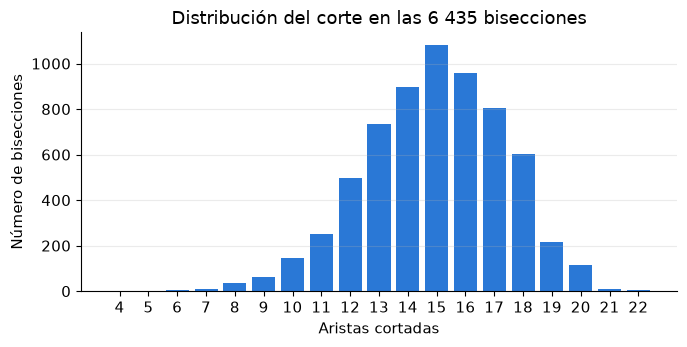

{4: 1, 5: 1, 6: 4, 7: 9, 8: 37, 9: 61, 10: 146, 11: 250, 12: 496, 13: 734, 14: 899, 15: 1083, 16: 960, 17: 805, 18: 604, 19: 214, 20: 117, 21: 11, 22: 3}


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
vals, cnt = np.unique(cortes, return_counts=True)
ax.bar(vals, cnt, color=AZUL, width=0.8)
ax.set_xlabel('Aristas cortadas'); ax.set_ylabel('Número de bisecciones')
ax.set_title('Distribución del corte en las 6 435 bisecciones')
ax.set_xticks(vals); ax.grid(axis='y', alpha=0.25)
fig.tight_layout(); fig.savefig(IMG / 'distribucion_cortes.png', dpi=200); plt.show()
print(dict(zip(vals.tolist(), cnt.tolist())))

## 4. Ejemplo: una iteración con 4 padres

Se reproduce paso a paso la iteración desarrollada a mano en el reporte (semilla 88, población de 4, $p_c=0.9$, $p_m=0.2$).

In [6]:
def cad(x): return ''.join(map(str, x))
def conj(x): return [i + 1 for i in range(N) if x[i]]

rng = np.random.default_rng(88)
padres = [inicializar(rng) for _ in range(4)]
print('Población inicial')
for k, x in enumerate(padres, 1):
    print(f'  P{k}: {cad(x)}  A={conj(x)}  f={corte(x)}  cortadas={[e for e in E if x[e[0]-1] != x[e[1]-1]]}')

log = []
nueva, hijos = generacion(padres, rng, pc=0.9, pm=0.2, log=log)
print('\nRegistro de la iteración:')
for paso in log:
    if paso[0] == 'torneo': print(f'  Torneo: P{paso[1]+1} vs P{paso[2]+1} -> gana P{paso[3]+1}')
    elif paso[0] == 'cruza': print(f'  Cruza: r = {paso[1]:.4f} -> punto k = {paso[2]}')
    elif paso[0] == 'reparar': print(f'  Reparación: exceso de unos = {paso[1]:+d}, genes invertidos = {paso[2]}')
    else: print(f'  Mutación: r = {paso[1]:.4f} -> ' + (f'intercambio nodos {paso[2]}' if paso[2] else 'no muta'))

Población inicial
  P1: 0010100011111100  A=[3, 5, 9, 10, 11, 12, 13, 14]  f=14  cortadas=[(1, 9), (1, 14), (2, 3), (2, 5), (3, 4), (3, 6), (3, 7), (5, 7), (7, 11), (8, 11), (12, 16), (13, 15), (13, 16), (14, 15)]
  P2: 1010110000110101  A=[1, 3, 5, 6, 11, 12, 14, 16]  f=20  cortadas=[(1, 2), (1, 9), (2, 3), (2, 5), (3, 4), (3, 7), (4, 6), (5, 7), (5, 9), (5, 10), (6, 7), (6, 8), (7, 11), (8, 11), (9, 14), (10, 11), (10, 12), (13, 16), (14, 15), (15, 16)]
  P3: 1010001100101011  A=[1, 3, 7, 8, 11, 13, 15, 16]  f=14  cortadas=[(1, 2), (1, 9), (1, 14), (2, 3), (3, 4), (3, 5), (3, 6), (5, 7), (6, 7), (6, 8), (9, 13), (10, 11), (12, 16), (14, 15)]
  P4: 1010100000111110  A=[1, 3, 5, 11, 12, 13, 14, 15]  f=19  cortadas=[(1, 2), (1, 9), (2, 3), (2, 5), (3, 4), (3, 6), (3, 7), (5, 7), (5, 9), (5, 10), (7, 11), (8, 11), (9, 13), (9, 14), (10, 11), (10, 12), (12, 16), (13, 16), (15, 16)]

Registro de la iteración:
  Torneo: P4 vs P2 -> gana P4
  Torneo: P1 vs P3 -> gana P1
  Cruza: r = 0.6558 -

In [7]:
# Reconstrucción explícita de los hijos antes y después de cada operador
rng = np.random.default_rng(88)
padres = [inicializar(rng) for _ in range(4)]
fit = [corte(x) for x in padres]
for par in range(2):
    a = torneo(padres, fit, rng); b = torneo(padres, fit, rng)
    r = rng.random(); k = int(rng.integers(1, N))
    h1 = np.concatenate([a[:k], b[k:]]); h2 = np.concatenate([b[:k], a[k:]])
    print(f'Par {par+1}: k = {k}')
    print(f'   padre a {cad(a[:k])}|{cad(a[k:])}')
    print(f'   padre b {cad(b[:k])}|{cad(b[k:])}')
    for h in (h1, h2):
        s0 = cad(h); u = int(h.sum()); h = reparar(h, rng); s1 = cad(h); h = mutar(h, 0.2, rng)
        print(f'   hijo {s0} (unos={u}) -> reparado {s1} -> final {cad(h)}  f={corte(h)}')

print('\nHijos:')
for k, h in enumerate(hijos, 1): print(f'  H{k}: {cad(h)}  A={conj(h)}  f={corte(h)}')
print('\nNueva población (reemplazo mu+lambda):')
for k, x in enumerate(nueva, 1): print(f'  {cad(x)}  A={conj(x)}  f={corte(x)}')
print(f'\nMejor: {min(map(corte, padres))} -> {min(map(corte, nueva))};  '
      f'promedio: {np.mean(list(map(corte, padres))):.2f} -> {np.mean(list(map(corte, nueva))):.2f}')

Par 1: k = 2
   padre a 10|10100000111110
   padre b 00|10100011111100
   hijo 1010100011111100 (unos=9) -> reparado 1010000011111100 -> final 1010000011111100  f=14
   hijo 0010100000111110 (unos=7) -> reparado 0010100010111110 -> final 0010100010111110  f=17
Par 2: k = 3
   padre a 001|0100011111100
   padre b 101|0001100101011
   hijo 0010001100101011 (unos=7) -> reparado 0010011100101011 -> final 0010011100101011  f=9
   hijo 1010100011111100 (unos=9) -> reparado 1010000011111100 -> final 1010001011011100  f=16

Hijos:
  H1: 1010000011111100  A=[1, 3, 9, 10, 11, 12, 13, 14]  f=14
  H2: 0010100010111110  A=[3, 5, 9, 11, 12, 13, 14, 15]  f=17
  H3: 0010011100101011  A=[3, 6, 7, 8, 11, 13, 15, 16]  f=9
  H4: 1010001011011100  A=[1, 3, 7, 9, 10, 12, 13, 14]  f=16

Nueva población (reemplazo mu+lambda):
  0010011100101011  A=[3, 6, 7, 8, 11, 13, 15, 16]  f=9
  0010100011111100  A=[3, 5, 9, 10, 11, 12, 13, 14]  f=14
  1010001100101011  A=[1, 3, 7, 8, 11, 13, 15, 16]  f=14
  1010000011111

## 5. AG con población de 20 individuos

Parámetros: población 20, $p_c=0.9$, $p_m=0.2$, máximo 100 generaciones o 30 generaciones consecutivas sin mejora del mejor
individuo. Se realizan 30 corridas independientes (semillas 0–29).

In [8]:
PARAM = dict(tam_pob=20, pc=0.9, pm=0.2, max_gen=100, sin_mejora=30)
resultados = []
for s in range(30):
    t0 = time.perf_counter()
    mejor, hm, hp = ag(semilla=s, **PARAM)
    t = time.perf_counter() - t0
    gen_opt = next((g + 1 for g, v in enumerate(hm) if v == OPT), None)
    resultados.append(dict(semilla=s, corte=corte(mejor), gens=len(hm), gen_opt=gen_opt, tiempo=t,
                           A=conj(mejor), hm=hm, hp=hp, x=mejor))

print(f"{'Sem':>3} {'Corte':>5} {'Gens':>5} {'GenÓpt':>7} {'Tiempo(s)':>10}  A")
for r in resultados:
    print(f"{r['semilla']:>3} {r['corte']:>5} {r['gens']:>5} {str(r['gen_opt']):>7} {r['tiempo']:>10.4f}  {r['A']}")
cs = np.array([r['corte'] for r in resultados]); ts = np.array([r['tiempo'] for r in resultados])
go = np.array([r['gen_opt'] for r in resultados if r['gen_opt']])
evals = np.array([PARAM['tam_pob'] * (1 + r['gens']) for r in resultados])
print(f'\nÉxito: {(cs == OPT).sum()}/30 corridas alcanzaron el óptimo ({OPT})')
print(f'Corte promedio: {cs.mean():.2f}; tiempo promedio: {ts.mean():.4f} ± {ts.std():.4f} s')
print(f'Generación en que se alcanza el óptimo: media {go.mean():.1f}, mín {go.min()}, máx {go.max()}, mediana {np.median(go):.0f}')
print(f'Generaciones totales (con el criterio de paro): media {np.mean([r["gens"] for r in resultados]):.1f}')
print(f'Evaluaciones de fitness promedio: {evals.mean():.0f} (vs 6 435 de la enumeración)')
print('Soluciones distintas encontradas:', {tuple(r['A']) for r in resultados})

Sem Corte  Gens  GenÓpt  Tiempo(s)  A
  0     4    37       7     0.0202  [1, 9, 10, 12, 13, 14, 15, 16]
  1     4    41      11     0.0212  [1, 9, 10, 12, 13, 14, 15, 16]
  2     4    46      16     0.0243  [1, 9, 10, 12, 13, 14, 15, 16]
  3     4    39       9     0.0201  [2, 3, 4, 5, 6, 7, 8, 11]
  4     4    67      37     0.0350  [2, 3, 4, 5, 6, 7, 8, 11]
  5     4    50      20     0.0223  [2, 3, 4, 5, 6, 7, 8, 11]
  6     4    53      23     0.0252  [1, 9, 10, 12, 13, 14, 15, 16]
  7     4    49      19     0.0216  [1, 9, 10, 12, 13, 14, 15, 16]
  8     4    35       5     0.0168  [2, 3, 4, 5, 6, 7, 8, 11]
  9     4    55      25     0.0242  [1, 9, 10, 12, 13, 14, 15, 16]
 10     4    48      18     0.0215  [1, 9, 10, 12, 13, 14, 15, 16]
 11     4    46      16     0.0206  [1, 9, 10, 12, 13, 14, 15, 16]
 12     4    37       7     0.0159  [1, 9, 10, 12, 13, 14, 15, 16]
 13     4    53      23     0.0238  [1, 9, 10, 12, 13, 14, 15, 16]
 14     4    37       7     0.0167  [2, 3, 4

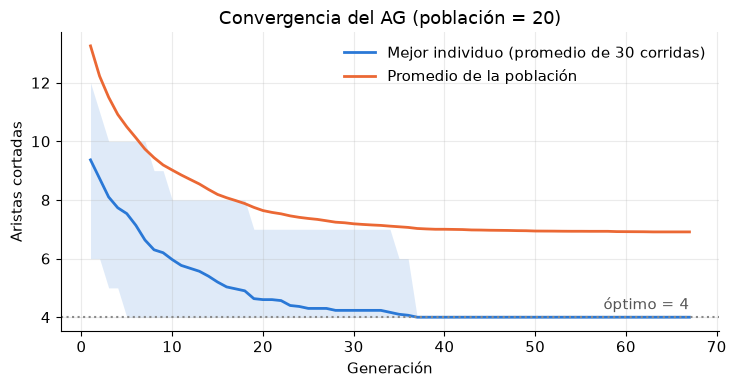

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
L = max(len(r['hm']) for r in resultados)
M = np.array([r['hm'] + [r['hm'][-1]] * (L - len(r['hm'])) for r in resultados])
Pm = np.array([r['hp'] + [r['hp'][-1]] * (L - len(r['hp'])) for r in resultados])
g = np.arange(1, L + 1)
ax.fill_between(g, M.min(0), M.max(0), color=AZUL, alpha=0.15, lw=0)
ax.plot(g, M.mean(0), color=AZUL, lw=2, label='Mejor individuo (promedio de 30 corridas)')
ax.plot(g, Pm.mean(0), color=NARANJA, lw=2, label='Promedio de la población')
ax.axhline(OPT, color=GRIS, ls=':', lw=1.5); ax.text(L, OPT + 0.15, f'óptimo = {OPT}', ha='right', va='bottom', color='#555')
ax.set_xlabel('Generación'); ax.set_ylabel('Aristas cortadas'); ax.set_title('Convergencia del AG (población = 20)')
ax.legend(frameon=False); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(IMG / 'convergencia.png', dpi=200); plt.show()

## 6. Mejor solución

A = [1, 9, 10, 12, 13, 14, 15, 16]
B = [2, 3, 4, 5, 6, 7, 8, 11]
Aristas cortadas: [(1, 2), (5, 9), (5, 10), (10, 11)] -> f = 4


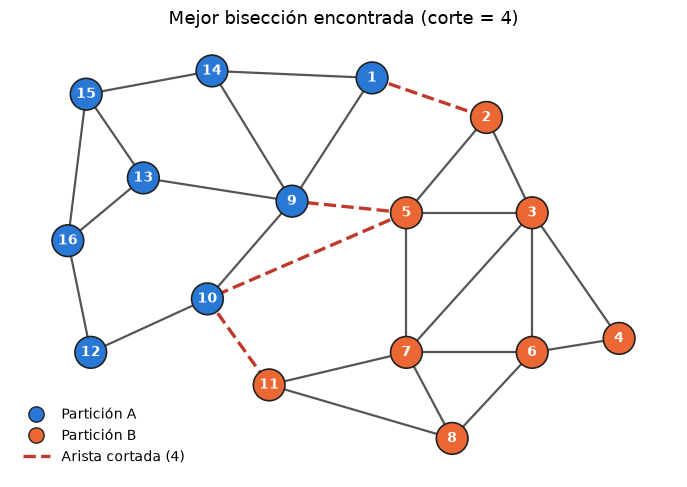

In [10]:
mejor = resultados[0]['x']
if mejor[0] == 0: mejor = 1 - mejor          # misma partición, nodo 1 en A
print('A =', conj(mejor)); print('B =', [i + 1 for i in range(N) if not mejor[i]])
print('Aristas cortadas:', [e for e in E if mejor[e[0]-1] != mejor[e[1]-1]], '-> f =', corte(mejor))
dibujar(mejor, titulo=f'Mejor bisección encontrada (corte = {corte(mejor)})', archivo='mejor_biseccion.png')